In [ ]:
# ============================================================
# STEP 0: Imports and Global Configuration
# ============================================================

import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# -----------------------------
# Reproducibility
# -----------------------------
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# -----------------------------
# Model & Image Parameters
# -----------------------------
IMG_SIZE = (224, 224)          # MobileNetV2 standard
BATCH_SIZE = 32
THRESHOLD = 0.5                # Fixed decision threshold

print("Environment ready.")


Environment ready.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

MODEL_PATH = "/content/drive/MyDrive/ResNet_Safe_Run/resnet_best.h5"
model = load_model(MODEL_PATH)

print("ResNet best model loaded successfully")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


ResNet best model loaded successfully


In [ ]:
# ============================================================
# STEP 2 (UPDATED): Evaluation + Confusion Matrix Visualization
# ============================================================

from sklearn.metrics import ConfusionMatrixDisplay

def evaluate_model_with_cm(model, generator, dataset_name):
    """
    Evaluates a binary classification model and plots confusion matrix.
    Assumptions:
    - Sigmoid output
    - Fresh = 0, Rotten = 1
    """

    # Reset generator
    generator.reset()

    # Predict probabilities
    y_prob = model.predict(generator, verbose=1).ravel()

    # Apply fixed threshold
    y_pred = (y_prob >= THRESHOLD).astype(int)

    # True labels
    y_true = generator.classes

    # Metrics
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred)

    # Print metrics
    print(f"\n📊 Results — {dataset_name}")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-score : {f1:.4f}")

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=["Fresh", "Rotten"]))

    # -----------------------------
    # Confusion Matrix Plot
    # -----------------------------
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Fresh", "Rotten"]
    )

    fig, ax = plt.subplots(figsize=(5, 4))
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    plt.title(f"Confusion Matrix — {dataset_name}")
    plt.show()

    return {
        "dataset": dataset_name,
        "accuracy": acc,
        "precision": prec,
        "recall": rec,
        "f1": f1,
        "confusion_matrix": cm
    }


In [ ]:
# ============================================================
# DATASET 1: MENDELEY TEST SET
# ============================================================

MENDELEY_TEST_DIR = "/content/drive/MyDrive/Final_Dataset/test"
# 🔁 CHANGE PATH if needed

test_datagen = ImageDataGenerator(rescale=1./255)

mendeley_test_gen = test_datagen.flow_from_directory(
    MENDELEY_TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)

print("Class mapping:", mendeley_test_gen.class_indices)


Found 848 images belonging to 2 classes.
Class mapping: {'Fresh': 0, 'Rotten': 1}


27/27 ━━━━━━━━━━━━━━━━━━━━ 298s 11s/step

📊 Results — Mendeley (In-distribution)
Accuracy : 0.7665
Precision: 0.8128
Recall   : 0.7037
F1-score : 0.7543

Classification Report:
              precision    recall  f1-score   support

       Fresh       0.73      0.83      0.78       416
      Rotten       0.81      0.70      0.75       432

    accuracy                           0.77       848
   macro avg       0.77      0.77      0.77       848
weighted avg       0.77      0.77      0.77       848



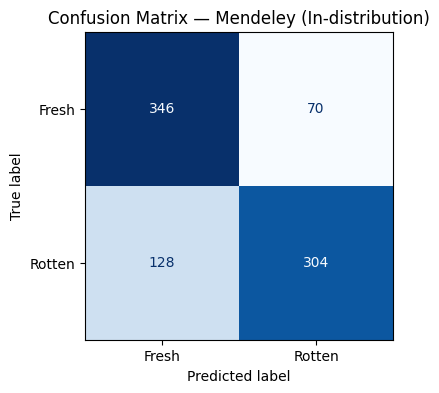

In [ ]:


mendeley_results = evaluate_model_with_cm(
    model,
    mendeley_test_gen,
    dataset_name="Mendeley (In-distribution)"
)


In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json


In [ ]:
!kaggle datasets download -d sriramr/fruits-fresh-and-rotten-for-classification


Dataset URL: https://www.kaggle.com/datasets/sriramr/fruits-fresh-and-rotten-for-classification
License(s): unknown
100% 3.58G/3.58G [00:19<00:00, 261MB/s]
100% 3.58G/3.58G [00:19<00:00, 200MB/s]


In [ ]:
!unzip fruits-fresh-and-rotten-for-classification.zip -d /content/kaggle_fruits


Streaming output truncated to the last 5000 lines.
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.02.09 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.02.18 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.02.24 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.02.37 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.02.51 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.03.02 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.03.12 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.03.2

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

test_dir = "/content/kaggle_fruits/dataset/test"

test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode=None,   # IMPORTANT
    shuffle=False
)


Found 2698 images belonging to 6 classes.


In [ ]:
import numpy as np

binary_labels = []

for path in test_generator.filepaths:
    folder = path.split("/")[-2].lower()

    if folder.startswith("fresh"):
        binary_labels.append(0)   # Fresh
    elif folder.startswith("rotten"):
        binary_labels.append(1)   # Rotten
    else:
        raise ValueError(f"Unknown class: {folder}")

y_true = np.array(binary_labels)


In [ ]:
y_prob = model.predict(test_generator, verbose=1)
y_pred = (y_prob >= 0.5).astype(int).flatten()


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


85/85 ━━━━━━━━━━━━━━━━━━━━ 576s 7s/step


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

print("Accuracy :", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred))
print("Recall   :", recall_score(y_true, y_pred))
print("F1-score :", f1_score(y_true, y_pred))

print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, target_names=["Fresh", "Rotten"]))


Accuracy : 0.5522609340252038
Precision: 0.7531055900621118
Recall   : 0.3161668839634941
F1-score : 0.44536271808999084

Classification Report:

              precision    recall  f1-score   support

       Fresh       0.49      0.86      0.62      1164
      Rotten       0.75      0.32      0.45      1534

    accuracy                           0.55      2698
   macro avg       0.62      0.59      0.53      2698
weighted avg       0.64      0.55      0.52      2698



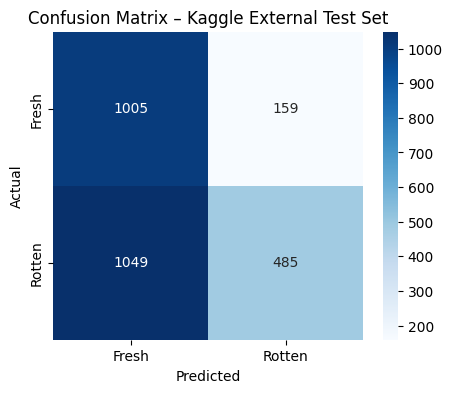

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fresh", "Rotten"],
    yticklabels=["Fresh", "Rotten"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix – Kaggle External Test Set")
plt.show()


In [ ]:
!kaggle datasets download -d riescoalieffe/fruitmate



Dataset URL: https://www.kaggle.com/datasets/riescoalieffe/fruitmate
License(s): unknown
  0% 0.00/12.6M [00:00<?, ?B/s]
100% 12.6M/12.6M [00:00<00:00, 1.04GB/s]


In [ ]:
!unzip fruitmate.zip -d /content/fruitmate


Archive:  fruitmate.zip
  inflating: /content/fruitmate/Testing/Overripe/Overripe004.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe006.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe007.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe008.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe011.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe012.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe021.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe022.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe023.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe027.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe028.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe029.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe036.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe038.jpeg  
  inflating: /content/fr

In [ ]:
import os

os.listdir("/content/fruitmate/Testing")


['Ripe', 'Overripe', 'Unripe']

In [ ]:
# ============================================================
# DATASET 3: FRUITMATE
# ============================================================

from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np

FRUITMATE_TEST_DIR = "/content/fruitmate/Testing"
# 🔁 CHANGE PATH if needed

test_datagen = ImageDataGenerator(rescale=1./255)

fruitmate_test_gen = test_datagen.flow_from_directory(
    FRUITMATE_TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode=None,   # intentional
    shuffle=False
)

print("Total FruitMate samples:", fruitmate_test_gen.samples)


Found 57 images belonging to 3 classes.
Total FruitMate samples: 57


In [ ]:
# ============================================================
# Construct Binary Labels
# ============================================================

binary_labels = []

for path in fruitmate_test_gen.filepaths:
    folder = path.split("/")[-2].lower()

    if "ripe" in folder and "over" not in folder:
        binary_labels.append(0)   # Fresh
    elif "overripe" in folder or "over_ripe" in folder:
        binary_labels.append(1)   # Rotten
    else:
        raise ValueError(f"Unrecognized class folder: {folder}")

y_true = np.array(binary_labels)


In [ ]:
# ============================================================
# Predict on FruitMate
# ============================================================

y_prob = model.predict(fruitmate_test_gen, verbose=1)
y_pred = (y_prob >= THRESHOLD).astype(int).ravel()


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


2/2 ━━━━━━━━━━━━━━━━━━━━ 11s 4s/step


📊 FruitMate Results
Accuracy : 0.6491228070175439
Precision: 0.4827586206896552
Recall   : 0.7368421052631579
F1-score : 0.5833333333333334

Classification Report:
              precision    recall  f1-score   support

       Fresh       0.82      0.61      0.70        38
      Rotten       0.48      0.74      0.58        19

    accuracy                           0.65        57
   macro avg       0.65      0.67      0.64        57
weighted avg       0.71      0.65      0.66        57



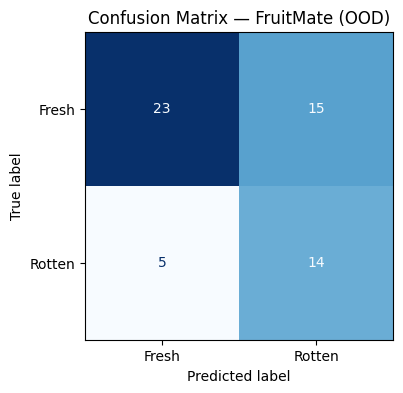

In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Metrics
acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred)
rec = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)
cm = confusion_matrix(y_true, y_pred)

print("📊 FruitMate Results")
print("Accuracy :", acc)
print("Precision:", prec)
print("Recall   :", rec)
print("F1-score :", f1)

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=["Fresh", "Rotten"]))

# Confusion Matrix Plot
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fresh", "Rotten"]
)

fig, ax = plt.subplots(figsize=(5, 4))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Confusion Matrix — FruitMate (OOD)")
plt.show()


In [ ]:
# Download Fruits Quality (Fresh vs Rotten)
!kaggle datasets download -d nourabdoun/fruits-quality-fresh-vs-rotten


Dataset URL: https://www.kaggle.com/datasets/nourabdoun/fruits-quality-fresh-vs-rotten
License(s): other
  0% 0.00/11.2M [00:00<?, ?B/s]
100% 11.2M/11.2M [00:00<00:00, 1.18GB/s]


In [ ]:
# Unzip dataset
!unzip -q fruits-quality-fresh-vs-rotten.zip -d /content/fruit_quality


In [ ]:
!ls "/content/fruit_quality/Quality Dataset/test"


fresh  rotten


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

TEST_DIR = "/content/fruit_quality/Quality Dataset/test"

test_datagen = ImageDataGenerator(rescale=1./255)

fruit_quality_test_gen = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=(224, 224),
    batch_size=32,
    class_mode="binary",
    shuffle=False
)

print("Class mapping:", fruit_quality_test_gen.class_indices)
print("Total samples:", fruit_quality_test_gen.samples)


Found 24 images belonging to 2 classes.
Class mapping: {'fresh': 0, 'rotten': 1}
Total samples: 24


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step

📊 Results — Fruit Quality (Kaggle OOD)
Accuracy : 0.3750
Precision: 0.3636
Recall   : 0.3333
F1-score : 0.3478

Classification Report:
              precision    recall  f1-score   support

       Fresh       0.38      0.42      0.40        12
      Rotten       0.36      0.33      0.35        12

    accuracy                           0.38        24
   macro avg       0.37      0.38      0.37        24
weighted avg       0.37      0.38      0.37        24



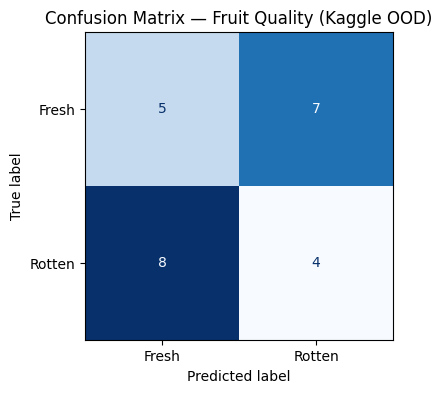

In [ ]:
fruit_quality_results = evaluate_model_with_cm(
    model,
    fruit_quality_test_gen,
    dataset_name="Fruit Quality (Kaggle OOD)"
)


In [ ]:
!unzip "/content/drive/MyDrive/Original Image -2.zip" -d "/content/fruitvision_raw"


Streaming output truncated to the last 5000 lines.
  inflating: /content/fruitvision_raw/Fruits Original/Grape/Fresh/msg5170347760-63714.jpg  
  inflating: /content/fruitvision_raw/Fruits Original/Grape/Fresh/msg5170347760-63715.jpg  
  inflating: /content/fruitvision_raw/Fruits Original/Grape/Fresh/msg5170347760-63716.jpg  
  inflating: /content/fruitvision_raw/Fruits Original/Grape/Fresh/msg5170347760-63717.jpg  
  inflating: /content/fruitvision_raw/Fruits Original/Grape/Fresh/msg5170347760-63718.jpg  
  inflating: /content/fruitvision_raw/Fruits Original/Grape/Fresh/msg5170347760-63719.jpg  
  inflating: /content/fruitvision_raw/Fruits Original/Grape/Fresh/msg5170347760-63720.jpg  
  inflating: /content/fruitvision_raw/Fruits Original/Grape/Fresh/msg5170347760-63721.jpg  
  inflating: /content/fruitvision_raw/Fruits Original/Grape/Fresh/msg5170347760-63722.jpg  
  inflating: /content/fruitvision_raw/Fruits Original/Grape/Fresh/msg5170347760-63723.jpg  
  inflating: /content/fruitvi

In [ ]:
import os

os.listdir("/content/fruitvision_raw")


['Fruits Original']

In [ ]:
SOURCE_DIR = "/content/fruitvision_raw/Fruits Original"
TARGET_DIR = "/content/fruitvision_test_clean"


In [ ]:
import os
import shutil

if os.path.exists(TARGET_DIR):
    shutil.rmtree(TARGET_DIR)

os.makedirs(os.path.join(TARGET_DIR, "Fresh"), exist_ok=True)
os.makedirs(os.path.join(TARGET_DIR, "Rotten"), exist_ok=True)


In [ ]:
for folder in os.listdir(SOURCE_DIR):
    folder_path = os.path.join(SOURCE_DIR, folder)
    if not os.path.isdir(folder_path):
        continue

    folder_lower = folder.lower()

    if folder_lower.startswith("fresh"):
        target_class = "Fresh"
    elif folder_lower.startswith("rotten"):
        target_class = "Rotten"
    else:
        # This skips all Formalin-mixed folders
        continue

    for img in os.listdir(folder_path):
        shutil.copy(
            os.path.join(folder_path, img),
            os.path.join(TARGET_DIR, target_class, img)
        )


In [ ]:
import os, shutil

TARGET_DIR = "/content/fruitvision_test_clean"

if os.path.exists(TARGET_DIR):
    shutil.rmtree(TARGET_DIR)

os.makedirs(os.path.join(TARGET_DIR, "Fresh"), exist_ok=True)
os.makedirs(os.path.join(TARGET_DIR, "Rotten"), exist_ok=True)


In [ ]:
SOURCE_DIR = "/content/fruitvision_raw/Fruits Original"

image_extensions = (".jpg", ".jpeg", ".png")

fresh_count = 0
rotten_count = 0

for root, dirs, files in os.walk(SOURCE_DIR):
    folder_name = os.path.basename(root).lower()

    if "formalin" in folder_name:
        continue

    if "fresh" in folder_name:
        target_class = "Fresh"
    elif "rotten" in folder_name:
        target_class = "Rotten"
    else:
        continue

    for file in files:
        if file.lower().endswith(image_extensions):
            src = os.path.join(root, file)
            dst = os.path.join(TARGET_DIR, target_class, file)
            shutil.copy(src, dst)

            if target_class == "Fresh":
                fresh_count += 1
            else:
                rotten_count += 1


In [ ]:
print("Fresh images copied :", fresh_count)
print("Rotten images copied:", rotten_count)


Fresh images copied : 3800
Rotten images copied: 3178


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    "/content/fruitvision_test_clean",
    target_size=(224, 224),
    batch_size=32,
    class_mode="binary",
    shuffle=False
)

print("Class indices:", test_generator.class_indices)


Found 6918 images belonging to 2 classes.
Class indices: {'Fresh': 0, 'Rotten': 1}


In [ ]:
y_prob = model.predict(test_generator, verbose=1)
y_pred = (y_prob >= 0.5).astype(int).flatten()
y_true = test_generator.classes


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


217/217 ━━━━━━━━━━━━━━━━━━━━ 1416s 7s/step


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(
    y_true,
    y_pred,
    target_names=["Fresh", "Rotten"]
))


              precision    recall  f1-score   support

       Fresh       0.70      0.52      0.59      3740
      Rotten       0.56      0.74      0.64      3178

    accuracy                           0.62      6918
   macro avg       0.63      0.63      0.62      6918
weighted avg       0.64      0.62      0.61      6918



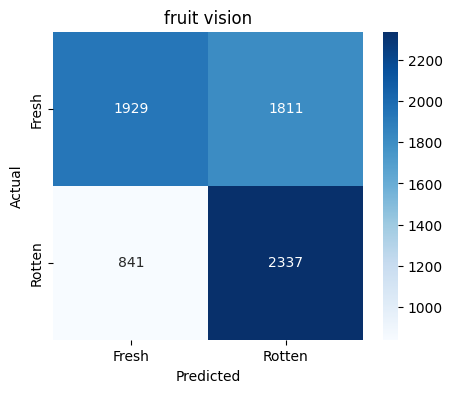

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fresh", "Rotten"],
    yticklabels=["Fresh", "Rotten"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("fruit vision")
plt.show()


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Fresh", "Rotten"],
            yticklabels=["Fresh", "Rotten"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("FruitVision – External Test Confusion Matrix")
plt.show()


In [ ]:
!kaggle datasets download -d amitsubhashagrahari/fresh-or-rotten-fruit


Dataset URL: https://www.kaggle.com/datasets/amitsubhashagrahari/fresh-or-rotten-fruit
License(s): apache-2.0
  0% 0.00/1.75M [00:00<?, ?B/s]
100% 1.75M/1.75M [00:00<00:00, 585MB/s]


In [ ]:
!unzip fresh-or-rotten-fruit.zip -d /content/fresh_rotten_external


Archive:  fresh-or-rotten-fruit.zip
  inflating: /content/fresh_rotten_external/Dataset_1/1.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/10.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/100.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/101.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/102.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/103.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/104.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/105.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/106.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/107.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/108.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/109.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/11.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/110.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/111.

In [ ]:
os.listdir("/content/fresh_rotten_external")


['Dataset_1']

In [ ]:
os.listdir("/content/fresh_rotten_external/Dataset_1")


['163.jpeg',
 '200.jpeg',
 '60.jpeg',
 '57.jpeg',
 '161.jpeg',
 '190.jpeg',
 '92.jpeg',
 '51.jpeg',
 '68.jpeg',
 '215.jpeg',
 '98.jpeg',
 '224.jpeg',
 '91.jpeg',
 '10.jpeg',
 '213.jpeg',
 '69.jpeg',
 '5.jpeg',
 '137.jpeg',
 '147.jpeg',
 '130.jpeg',
 '170.jpeg',
 '165.jpeg',
 '41.jpeg',
 '70.jpeg',
 '89.jpeg',
 '184.jpeg',
 '76.jpeg',
 '201.jpeg',
 '30.jpeg',
 '24.jpeg',
 '80.jpeg',
 '32.jpeg',
 '139.jpeg',
 '111.jpeg',
 '23.jpeg',
 '12.jpeg',
 '156.jpeg',
 '132.jpeg',
 '220.jpeg',
 '15.jpeg',
 '29.jpeg',
 '33.jpeg',
 '93.jpeg',
 '122.jpeg',
 '109.jpeg',
 '136.jpeg',
 '171.jpeg',
 '11.jpeg',
 '149.jpeg',
 '180.jpeg',
 '223.jpeg',
 '107.jpeg',
 '65.jpeg',
 '79.jpeg',
 '185.jpeg',
 '229.jpeg',
 '154.jpeg',
 '114.jpeg',
 '4.jpeg',
 '110.jpeg',
 '42.jpeg',
 '9.jpeg',
 '182.jpeg',
 '3.jpeg',
 '172.jpeg',
 '47.jpeg',
 '71.jpeg',
 '66.jpeg',
 '157.jpeg',
 '209.jpeg',
 '227.jpeg',
 '207.jpeg',
 '54.jpeg',
 '173.jpeg',
 '82.jpeg',
 '124.jpeg',
 '202.jpeg',
 '164.jpeg',
 '230',
 '38.jpeg',
 '77.j

In [ ]:
os.listdir("/content/fresh_rotten_external")


['Dataset_1']

In [ ]:
os.listdir("/content/fresh_rotten_external/Dataset_1")


['163.jpeg',
 '200.jpeg',
 '60.jpeg',
 '57.jpeg',
 '161.jpeg',
 '190.jpeg',
 '92.jpeg',
 '51.jpeg',
 '68.jpeg',
 '215.jpeg',
 '98.jpeg',
 '224.jpeg',
 '91.jpeg',
 '10.jpeg',
 '213.jpeg',
 '69.jpeg',
 '5.jpeg',
 '137.jpeg',
 '147.jpeg',
 '130.jpeg',
 '170.jpeg',
 '165.jpeg',
 '41.jpeg',
 '70.jpeg',
 '89.jpeg',
 '184.jpeg',
 '76.jpeg',
 '201.jpeg',
 '30.jpeg',
 '24.jpeg',
 '80.jpeg',
 '32.jpeg',
 '139.jpeg',
 '111.jpeg',
 '23.jpeg',
 '12.jpeg',
 '156.jpeg',
 '132.jpeg',
 '220.jpeg',
 '15.jpeg',
 '29.jpeg',
 '33.jpeg',
 '93.jpeg',
 '122.jpeg',
 '109.jpeg',
 '136.jpeg',
 '171.jpeg',
 '11.jpeg',
 '149.jpeg',
 '180.jpeg',
 '223.jpeg',
 '107.jpeg',
 '65.jpeg',
 '79.jpeg',
 '185.jpeg',
 '229.jpeg',
 '154.jpeg',
 '114.jpeg',
 '4.jpeg',
 '110.jpeg',
 '42.jpeg',
 '9.jpeg',
 '182.jpeg',
 '3.jpeg',
 '172.jpeg',
 '47.jpeg',
 '71.jpeg',
 '66.jpeg',
 '157.jpeg',
 '209.jpeg',
 '227.jpeg',
 '207.jpeg',
 '54.jpeg',
 '173.jpeg',
 '82.jpeg',
 '124.jpeg',
 '202.jpeg',
 '164.jpeg',
 '230',
 '38.jpeg',
 '77.j

In [ ]:
dataset_dir = "/content/fresh_rotten_external/Dataset_1"

all_images = [f for f in os.listdir(dataset_dir) if f.lower().endswith(".jpeg")]
print("Total images in dataset:", len(all_images))


Total images in dataset: 229


In [ ]:
dataset_dir = "/content/fresh_rotten_external/Dataset_1"

all_images = [f for f in os.listdir(dataset_dir) if f.lower().endswith(".jpeg")]
print("Total images in dataset:", len(all_images))


Total images in dataset: 229


In [ ]:
import os

dataset_dir = "/content/fresh_rotten_external/Dataset_1"

image_paths = [
    os.path.join(dataset_dir, f)
    for f in os.listdir(dataset_dir)
    if f.lower().endswith(".jpeg")
]

print("Total images in qualitative dataset:", len(image_paths))


Total images in qualitative dataset: 229


In [ ]:
import numpy as np
from tensorflow.keras.preprocessing import image

def predict_image(img_path, model):
    img = image.load_img(img_path, target_size=(224, 224))
    img_arr = image.img_to_array(img) / 255.0
    img_arr = np.expand_dims(img_arr, axis=0)

    prob = model.predict(img_arr, verbose=0)[0][0]

    label = "Rotten" if prob >= 0.5 else "Fresh"
    confidence = prob if label == "Rotten" else 1 - prob

    return label, confidence


In [ ]:
results = []

for img_path in image_paths:
    label, conf = predict_image(img_path, model)
    results.append({
        "image": os.path.basename(img_path),
        "predicted_label": label,
        "confidence": conf
    })


In [ ]:
import pandas as pd

df_results = pd.DataFrame(results)
df_results


,image,predicted_label,confidence
0,163.jpeg,Rotten,0.518007
1,200.jpeg,Rotten,0.528434
2,60.jpeg,Rotten,0.763078
3,57.jpeg,Rotten,0.864414
4,161.jpeg,Fresh,0.872441
...,...,...,...
224,155.jpeg,Rotten,0.576548
225,121.jpeg,Fresh,0.773202
226,97.jpeg,Fresh,0.954515
227,6.jpeg,Rotten,0.836030


In [ ]:
df_results["predicted_label"].value_counts()


,count
predicted_label,
Rotten,141
Fresh,88


In [ ]:
df_results.groupby("predicted_label")["confidence"].describe()


,count,mean,std,min,25%,50%,75%,max
predicted_label,,,,,,,,
Fresh,88.0,0.718558,0.149391,0.503428,0.585044,0.703648,0.856910,0.985505
Rotten,141.0,0.723852,0.135564,0.501395,0.603486,0.721084,0.828332,0.999226


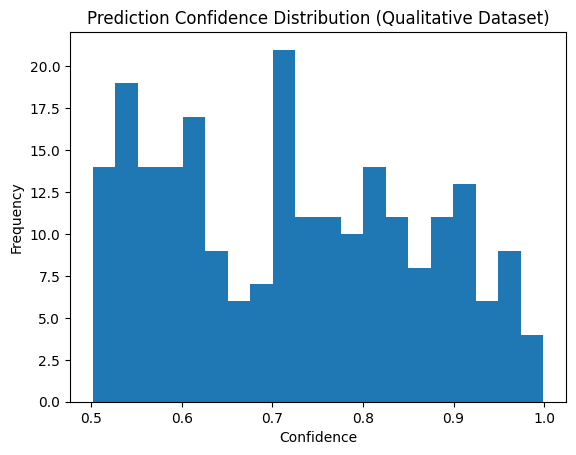

In [ ]:
import matplotlib.pyplot as plt

plt.hist(df_results["confidence"], bins=20)
plt.title("Prediction Confidence Distribution (Qualitative Dataset)")
plt.xlabel("Confidence")
plt.ylabel("Frequency")
plt.show()


In [ ]:
import numpy as np
import tensorflow as tf

img_path = "/content/drive/MyDrive/apple-gone-bad.jpg"  # rotten image

img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224,224))
img_arr = tf.keras.preprocessing.image.img_to_array(img)
img_arr = np.expand_dims(img_arr, axis=0)
img_arr = img_arr / 255.0

pred = model.predict(img_arr)
print("Raw sigmoid output:", pred[0][0])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 410ms/step
Raw sigmoid output: 0.2407377


In [ ]:
import numpy as np
import tensorflow as tf

img_path = "/content/drive/MyDrive/WhatsApp Image 2026-01-23 at 19.48.56.jpeg"  # rotten image

img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224,224))
img_arr = tf.keras.preprocessing.image.img_to_array(img)
img_arr = np.expand_dims(img_arr, axis=0)
img_arr = img_arr / 255.0

pred = model.predict(img_arr)
print("Raw sigmoid output:", pred[0][0])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 420ms/step
Raw sigmoid output: 0.14244817


In [ ]:
import numpy as np
import tensorflow as tf

img_path = "/content/drive/MyDrive/WhatsApp Image 2026-01-23 at 19.48.56 (1).jpeg"  # rotten image

img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224,224))
img_arr = tf.keras.preprocessing.image.img_to_array(img)
img_arr = np.expand_dims(img_arr, axis=0)
img_arr = img_arr / 255.0

pred = model.predict(img_arr)
print("Raw sigmoid output:", pred[0][0])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 251ms/step
Raw sigmoid output: 0.39626062


In [ ]:
import numpy as np
import tensorflow as tf

img_path = "/content/drive/MyDrive/WhatsApp Image 2026-01-23 at 19.48.55.jpeg"  # rotten image

img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224,224))
img_arr = tf.keras.preprocessing.image.img_to_array(img)
img_arr = np.expand_dims(img_arr, axis=0)
img_arr = img_arr / 255.0

pred = model.predict(img_arr)
print("Raw sigmoid output:", pred[0][0])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step
Raw sigmoid output: 0.25690898


In [ ]:
import numpy as np
import tensorflow as tf

img_path = "/content/drive/MyDrive/rakshit_check.png"  # rotten image

img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224,224))
img_arr = tf.keras.preprocessing.image.img_to_array(img)
img_arr = np.expand_dims(img_arr, axis=0)
img_arr = img_arr / 255.0

pred = model.predict(img_arr)
print("Raw sigmoid output:", pred[0][0])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step
Raw sigmoid output: 0.51772994
